In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import plotly.express as px

pd.set_option("display.max_columns", None)

In [6]:
train = pd.read_csv("../data/train.csv")

test = pd.read_csv("../data/test.csv")

store = pd.read_csv("../data/store.csv")

In [7]:
print(train.shape)
print(test.shape)
print(store.shape)

(1017209, 9)
(41088, 8)
(1115, 10)


In [8]:
train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB


In [10]:
train.describe(include="all")

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
count,1.017209e+06,1.017209e+06,1017209,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1017209,1.017209e+06
unique,NaN,NaN,942,NaN,NaN,NaN,NaN,5,NaN
top,NaN,NaN,2013-01-02,NaN,NaN,NaN,NaN,0,NaN
freq,NaN,NaN,1115,NaN,NaN,NaN,NaN,855087,NaN
mean,5.584297e+02,3.998341e+00,NaN,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,NaN,1.786467e-01
std,3.219087e+02,1.997391e+00,NaN,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,NaN,3.830564e-01
min,1.000000e+00,1.000000e+00,NaN,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN,0.000000e+00
25%,2.800000e+02,2.000000e+00,NaN,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,NaN,0.000000e+00
50%,5.580000e+02,4.000000e+00,NaN,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,NaN,0.000000e+00
75%,8.380000e+02,6.000000e+00,NaN,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,NaN,0.000000e+00


In [11]:
train.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [12]:
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [13]:
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assortment                 1115 non-null   object 
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    object 
dtypes: float64(5), int64(2), object(3)
memory usage: 87.2+ KB


In [14]:
df = train.merge(
    store,
    on="Store",
    how="left"
)

df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [15]:
print(df.shape)

(1017209, 18)


In [16]:
print("="*50)
print("TRAIN DATA")
print("="*50)

print(f"Rows: {train.shape[0]:,}")
print(f"Columns: {train.shape[1]}")

print("\nUnique Stores:", train["Store"].nunique())

print("Date Range:")
print(train["Date"].min(), "to", train["Date"].max())

print("\nTarget Variable:")
print(train["Sales"].describe())

TRAIN DATA
Rows: 1,017,209
Columns: 9

Unique Stores: 1115
Date Range:
2013-01-01 to 2015-07-31

Target Variable:
count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64


### **Observations**

- The dataset contains over 1 million sales records.
- Sales is the target variable.
- Data spans multiple years, allowing seasonal trend analysis.
- Multiple stores are represented, making this a multi-store forecasting problem.

In [20]:
missing = df.isnull().sum().sort_values(ascending=False)

missing = missing[missing > 0]

missing

Promo2SinceWeek              508031
PromoInterval                508031
Promo2SinceYear              508031
CompetitionOpenSinceYear     323348
CompetitionOpenSinceMonth    323348
CompetitionDistance            2642
dtype: int64

In [19]:
missing_percentage = (
    df.isnull().sum()/len(df)
)*100

missing_percentage = missing_percentage.sort_values(ascending=False)

missing_percentage = missing_percentage[missing_percentage>0]

missing_percentage

Promo2SinceWeek              49.943620
PromoInterval                49.943620
Promo2SinceYear              49.943620
CompetitionOpenSinceYear     31.787764
CompetitionOpenSinceMonth    31.787764
CompetitionDistance           0.259730
dtype: float64

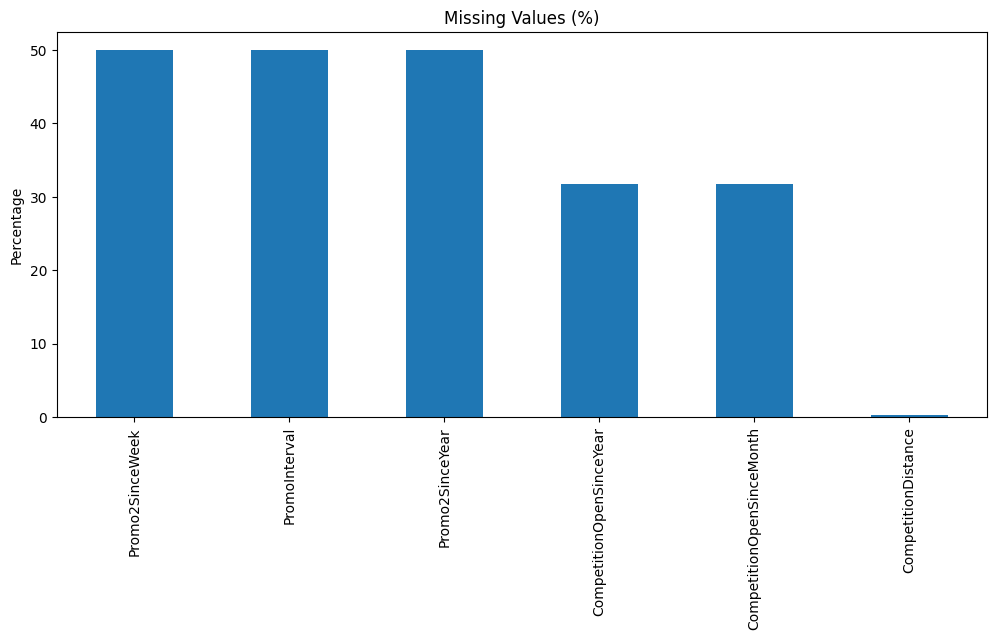

In [22]:
missing_percentage.plot(
    kind="bar",
    figsize=(12,5),
    title="Missing Values (%)"
)

plt.ylabel("Percentage")
plt.show()

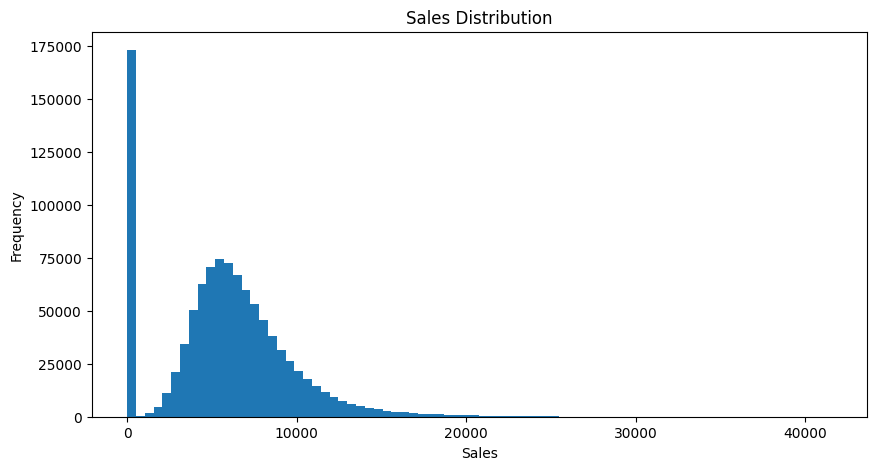

In [23]:
plt.figure(figsize=(10,5))

plt.hist(
    train["Sales"],
    bins=80
)

plt.title("Sales Distribution")

plt.xlabel("Sales")

plt.ylabel("Frequency")

plt.show()

In [24]:
train["Open"].value_counts()

Open
1    844392
0    172817
Name: count, dtype: int64

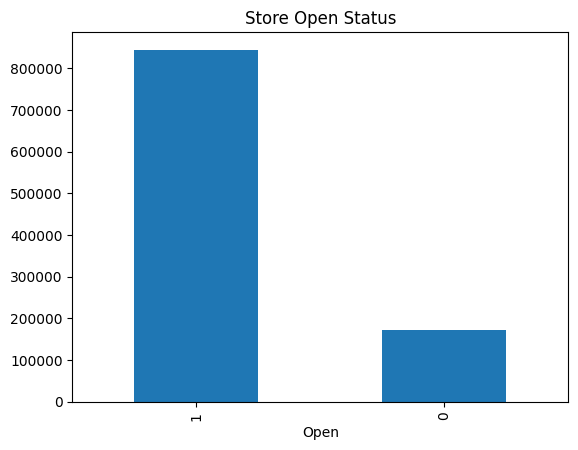

In [25]:
train["Open"].value_counts().plot(
    kind="bar",
    title="Store Open Status"
)

plt.show()

In [26]:
train["SchoolHoliday"].value_counts()

SchoolHoliday
0    835488
1    181721
Name: count, dtype: int64

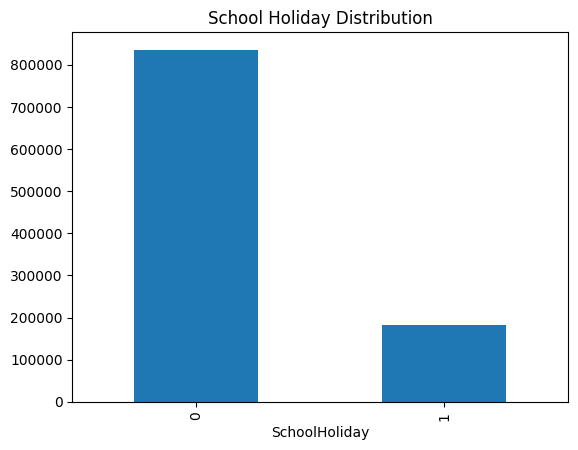

In [27]:
train["SchoolHoliday"].value_counts().plot(
    kind="bar",
    title="School Holiday Distribution"
)

plt.show()

In [30]:
train["Promo"].value_counts()

Promo
0    629129
1    388080
Name: count, dtype: int64

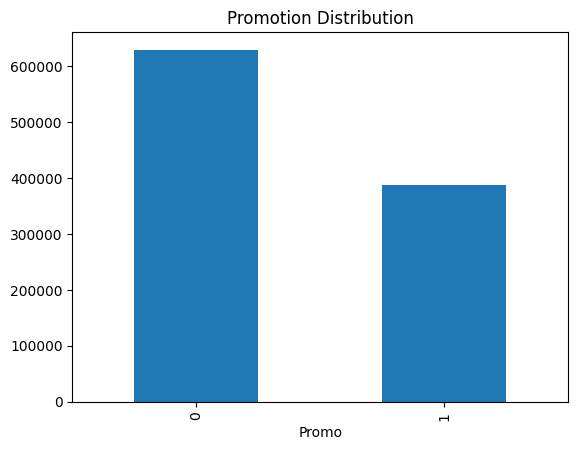

In [33]:
train["Promo"].value_counts().plot(
    kind="bar",
    title="Promotion Distribution"
)

plt.show()

In [28]:
store["StoreType"].value_counts()

StoreType
a    602
d    348
c    148
b     17
Name: count, dtype: int64

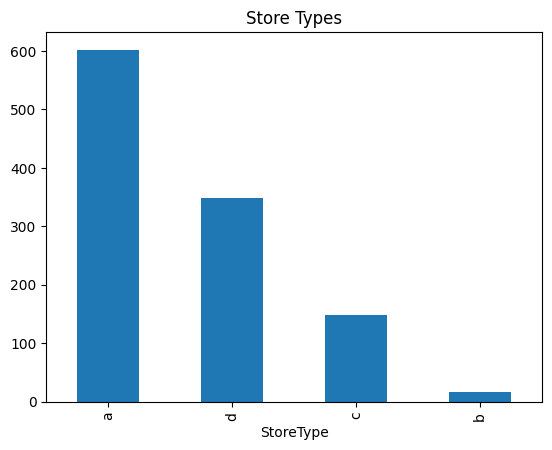

In [29]:
store["StoreType"].value_counts().plot(
    kind="bar",
    title="Store Types"
)

plt.show()

In [34]:
train["Date"] = pd.to_datetime(train["Date"])

daily_sales = train.groupby("Date")["Sales"].sum().reset_index()

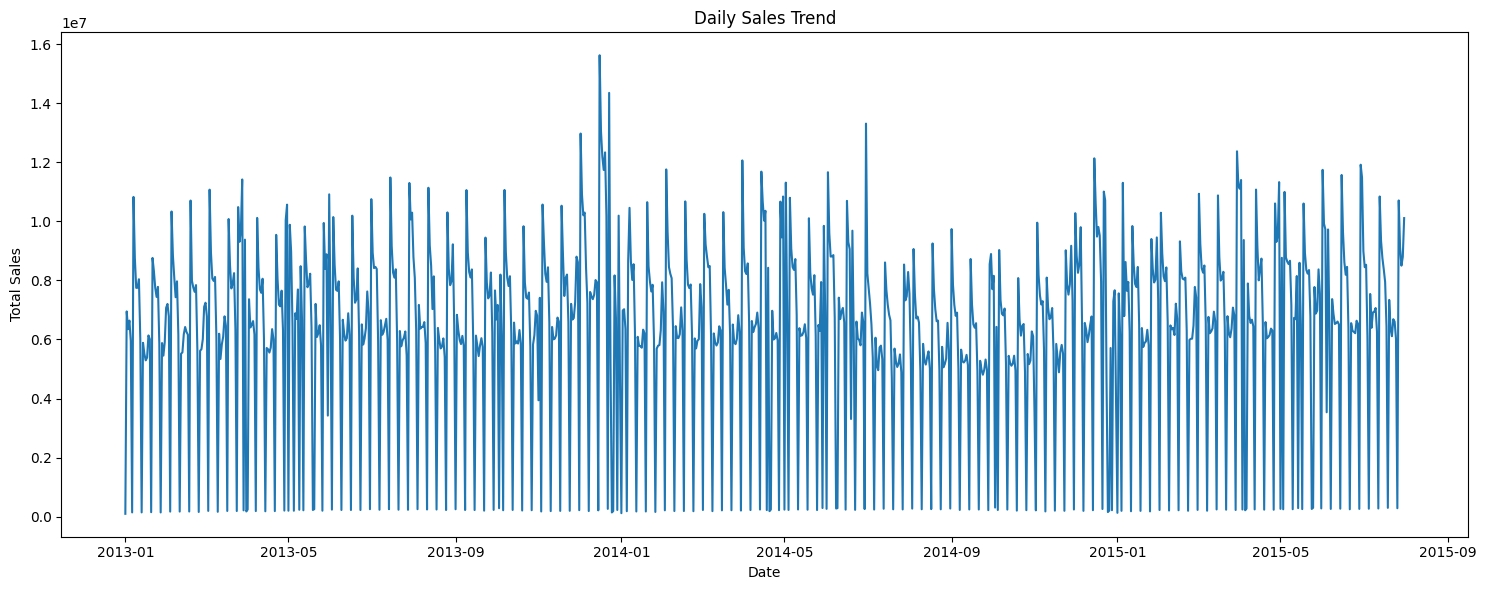

In [35]:
plt.figure(figsize=(15,6))

plt.plot(
    daily_sales["Date"],
    daily_sales["Sales"]
)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

In [36]:
train["DayName"] = train["Date"].dt.day_name()

In [37]:
weekday_sales = train.groupby("DayName")["Sales"].mean()

weekday_sales = weekday_sales.reindex([
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
])

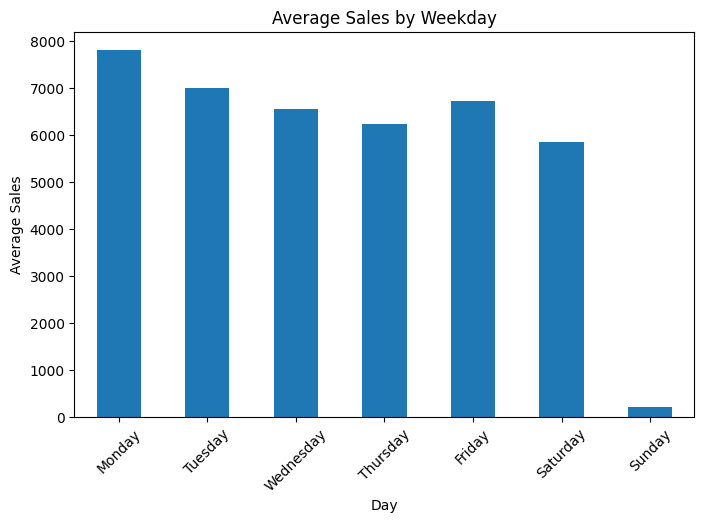

In [38]:
plt.figure(figsize=(8,5))

weekday_sales.plot(kind="bar")

plt.title("Average Sales by Weekday")

plt.xlabel("Day")

plt.ylabel("Average Sales")

plt.xticks(rotation=45)

plt.show()

In [39]:
train["Month"] = train["Date"].dt.month_name()

In [40]:
month_sales = train.groupby("Month")["Sales"].mean()

month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

month_sales = month_sales.reindex(month_order)

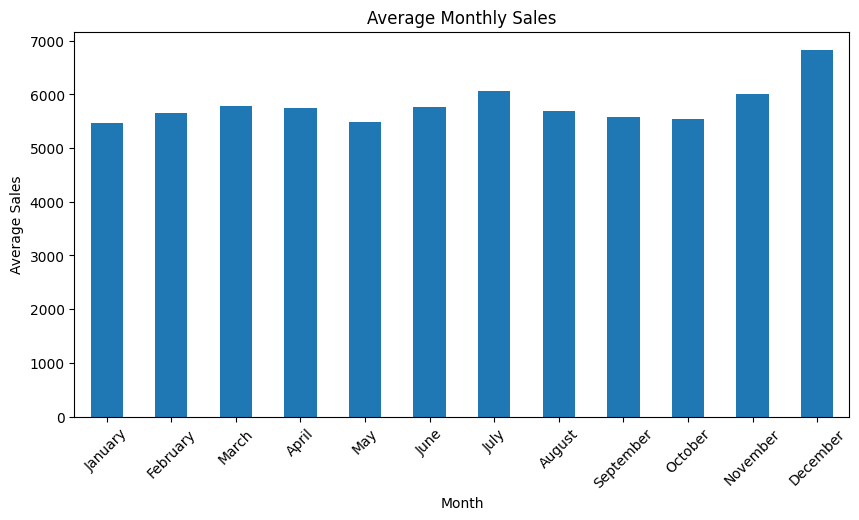

In [41]:
plt.figure(figsize=(10,5))

month_sales.plot(kind="bar")

plt.title("Average Monthly Sales")

plt.xlabel("Month")

plt.ylabel("Average Sales")

plt.xticks(rotation=45)

plt.show()

In [42]:
promo_sales = train.groupby("Promo")["Sales"].mean()

promo_sales

Promo
0    4406.050805
1    7991.152046
Name: Sales, dtype: float64

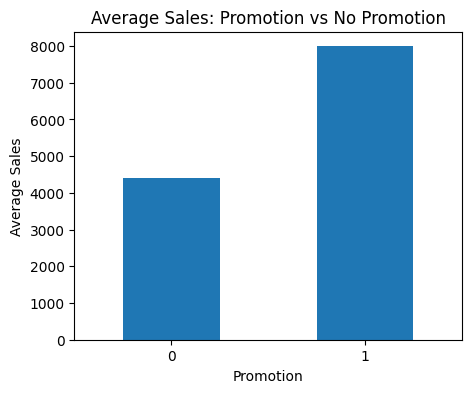

In [43]:
plt.figure(figsize=(5,4))

promo_sales.plot(kind="bar")

plt.title("Average Sales: Promotion vs No Promotion")

plt.xlabel("Promotion")

plt.ylabel("Average Sales")

plt.xticks(rotation=0)

plt.show()

In [44]:
top_store = (
    train.groupby("Store")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

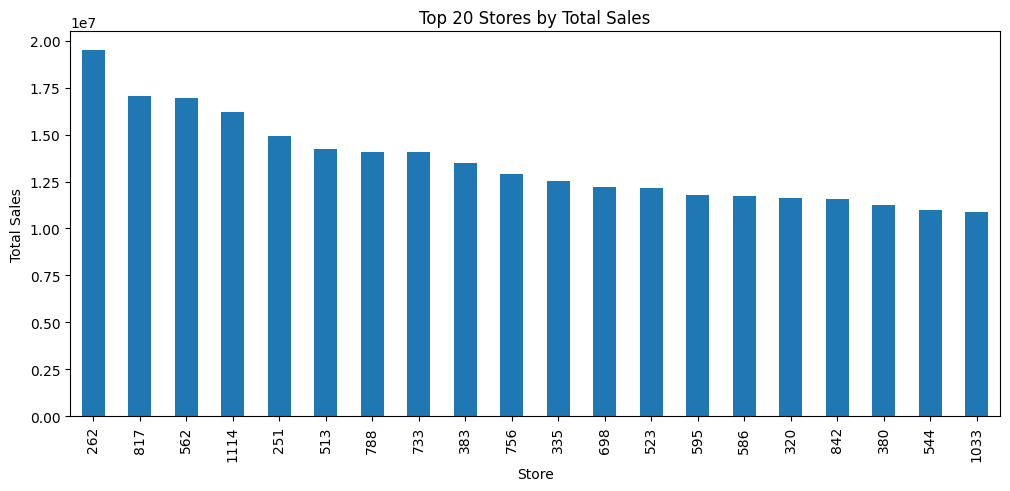

In [45]:
plt.figure(figsize=(12,5))

top_store.plot(kind="bar")

plt.title("Top 20 Stores by Total Sales")

plt.xlabel("Store")

plt.ylabel("Total Sales")

plt.show()

In [46]:
store_sales = df.groupby("StoreType")["Sales"].mean()

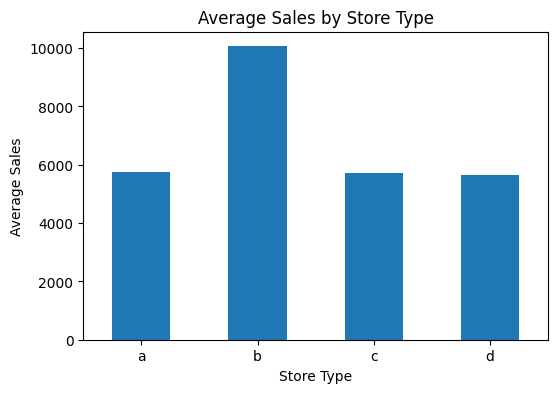

In [47]:
plt.figure(figsize=(6,4))

store_sales.plot(kind="bar")

plt.title("Average Sales by Store Type")

plt.xlabel("Store Type")

plt.ylabel("Average Sales")

plt.xticks(rotation=0)

plt.show()

### **Key Business Insights**

1. Sales exhibit clear weekly and yearly seasonality.
2. Promotional campaigns significantly increase average sales.
3. Different store types have distinct sales patterns.
4. Closed stores almost always report zero sales.
5. Missing values correspond to store business characteristics rather than random errors.
6. Sales distribution is highly right-skewed with notable outliers.